# Part 4.B — DINOv2 ViT-S/14 features + linear SVM

Stage B of Part 4 replaces the supervised ResNet-18 with a **self-supervised**
DINOv2 ViT-S/14 backbone. The protocol is identical to Stage A:

* features are extracted once, frozen, and cached;
* positives = target category, negatives = `background`, labels `+1` / `-1`;
* `C` is selected on the **same internal validation split** carved out of `*_train`
  (selected by file name, so the split does not depend on cache row order);
* the supplied `*_val` split is the final **test** set and is scored once;
* AP is `sklearn.metrics.average_precision_score`.

The descriptor is the **384-D CLS token**. In the same forward pass the notebook
also pools the 256 patch tokens (mean and GeM) so the optional
"global vs aggregated patches" comparison costs no extra extraction.

Outputs: per-class AP + mAP, PR curve, ranked grid, 6-way confusion matrix,
normalisation ablation, pooling ablation, cost/storage table, and rows for the
consolidated comparison table — all written to `results/`.

In [1]:
import json
import os
import sys
import time
from pathlib import Path


def _find_code_dir():
    '''Locate the directory containing src/ (works from code/ or the repo root).'''
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        for candidate in (base, base / "code"):
            if (candidate / "src" / "deep_models.py").exists():
                return candidate
    raise FileNotFoundError(
        "Could not find src/deep_models.py. Open the notebook from code/ or the repo root."
    )


CODE_DIR = _find_code_dir()
if str(CODE_DIR) not in sys.path:
    sys.path.insert(0, str(CODE_DIR))
os.chdir(CODE_DIR)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from src.deep_models import getModel
from src.deep_eval import (
    CATEGORIES,
    binary_subset,
    evaluate_binary,
    evaluate_multiclass,
    internal_val_names,
    l2norm,
    per_class_table,
    save_results,
    storage_mb,
)
from src.visualization import displayPrecisionRecallCurve, displayRankedImageList

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# --------------------------- experiment configuration -----------------------
CATEGORY = "motorbike"
CATEGORIES_TO_EVAL = CATEGORIES
TAG = "dinov2_vits14"
POOLINGS = ("cls", "mean", "gem")
GEM_P = 3.0                            # GeM exponent (fixed a priori)
BATCH_SIZE = 32
MAX_ITER = 5000
SEED = 0
VAL_FRACTION = 0.2
C_GRID = (0.1, 1.0, 10.0, 100.0, 1000.0)
RUN_NORMALISATION_ABLATION = True
RUN_POOLING_ABLATION = True
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 110

Device: cpu


## B.1 — Load the frozen DINOv2 backbone

`getModel("dinov2_vits14")` loads ViT-S/14 through Torch Hub with the official
preprocessing (**Resize 256 → CenterCrop 224 → Normalize**) and puts the model in
`eval()` mode. No weight is ever updated.

The cell also inspects the raw output once (some Torch Hub versions return a
tensor, others a dict) and records the model-loading time separately — it must
not be reported as per-image extraction cost.

In [2]:
t0 = time.perf_counter()
model, preprocess = getModel("dinov2_vits14", device)
model.eval()
model_load_s = time.perf_counter() - t0

n_params = sum(p.numel() for p in model.parameters())
print(f"ViT-S/14 parameters: {n_params/1e6:.1f} M")
print(f"Model load: {model_load_s:.2f}s")
print("Preprocessing:", preprocess)

probe = preprocess(Image.open("data/images/000007.jpg").convert("RGB")).unsqueeze(0).to(device)
with torch.inference_mode():
    raw = model(probe)
print("forward() ->", type(raw).__name__,
      tuple(raw.shape) if torch.is_tensor(raw) else
      {k: tuple(v.shape) for k, v in raw.items() if torch.is_tensor(v)})

if hasattr(model, "forward_features"):
    with torch.inference_mode():
        ff = model.forward_features(probe)
    print("forward_features() ->",
          {k: tuple(v.shape) for k, v in ff.items() if torch.is_tensor(v)}
          if isinstance(ff, dict) else tuple(ff.shape))

Using cache found in C:\Users\HP/.cache\torch\hub\facebookresearch_dinov2_main


ViT-S/14 parameters: 22.1 M
Model load: 1.47s
Preprocessing: Compose(
    Resize(size=256, interpolation=bilinear, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)
forward() -> Tensor (1, 384)
forward_features() -> {'x_norm_clstoken': (1, 384), 'x_norm_regtokens': (1, 0, 384), 'x_norm_patchtokens': (1, 256, 384), 'x_prenorm': (1, 257, 384)}


## B.2 — Extract and cache CLS / mean / GeM descriptors

One forward pass per image produces all three descriptors, so the pooling
ablation later is free:

* `cls` — the 384-D global CLS token (main representation);
* `mean` — average of the 16 × 16 = 256 patch tokens;
* `gem` — generalised-mean pooling (fixed exponent p = 3) of the
  ReLU-rectified patch tokens (GeM is defined for non-negative features).

Everything is cached under `data/deep_features/<TAG>/<split>.npz` with
`file_names`, `categories` and a `meta.json` holding the measured extraction
cost (preprocessing included). On CPU this pass takes roughly 10–20 minutes for
the ~5 600 train+test images; it is done once.

In [3]:
def _pool_descriptors(x):
    '''One forward pass -> dict of {'cls','mean','gem'} float tensors of shape (B, 384).'''
    if hasattr(model, "forward_features"):
        feats = model.forward_features(x)
    else:
        feats = model(x)

    if isinstance(feats, dict):
        cls = feats.get("x_norm_clstoken", feats.get("cls_token"))
        patches = feats.get("x_norm_patchtokens", feats.get("patch_tokens"))
    elif torch.is_tensor(feats) and feats.dim() == 3:
        cls, patches = feats[:, 0], feats[:, 1:]
    else:
        cls, patches = feats, None

    if cls is None:
        raise RuntimeError("Could not find the CLS token in the DINOv2 output")

    out = {"cls": cls}
    if patches is not None:
        out["mean"] = patches.mean(dim=1)
        out["gem"] = patches.relu().clamp(min=1e-6).pow(GEM_P).mean(dim=1).pow(1.0 / GEM_P)
    return {k: v.float() for k, v in out.items()}


def extract_split(df, batch_size=BATCH_SIZE):
    '''Return ({pooling: (N, 384) float32}, seconds) for one split.'''
    acc = {k: [] for k in POOLINGS}
    t0 = time.perf_counter()
    with torch.inference_mode():
        for start in range(0, len(df), batch_size):
            batch = df.iloc[start:start + batch_size]
            images = [preprocess(Image.open(p).convert("RGB")) for p in batch.filepath]
            x = torch.stack(images).to(device)
            descs = _pool_descriptors(x)
            for key in acc:
                if key in descs:
                    acc[key].append(descs[key].cpu().numpy().astype(np.float32))
            if (start // batch_size) % 25 == 0:
                print(f"  {min(start + len(batch), len(df)):5d}/{len(df)}", end="\r")
    dt = time.perf_counter() - t0
    feats = {k: np.concatenate(v, axis=0) for k, v in acc.items() if v}
    dim = next(iter(feats.values())).shape[1]
    print(f"  done: {len(df)} images, {dim}-D, {dt:.1f}s "
          f"({1000 * dt / max(len(df), 1):.1f} ms/img, preprocessing included)")
    return feats, dt


def _read_meta(cache_dir):
    meta_file = Path(cache_dir) / "meta.json"
    return json.loads(meta_file.read_text()) if meta_file.exists() else {}


def get_features(subset, tag=TAG, pooling="cls", force=False):
    '''Return (features, file_names, categories, meta) for one pooling.'''
    if pooling not in POOLINGS:
        raise ValueError(f"pooling must be one of {POOLINGS}")
    cache_dir = Path("data/deep_features") / tag
    cache = cache_dir / f"{subset}.npz"
    cache_dir.mkdir(parents=True, exist_ok=True)
    key = f"features_{pooling}"
    meta = _read_meta(cache_dir)

    if cache.exists() and not force:
        features = file_names = categories = None
        with np.load(cache, allow_pickle=True) as data:
            if key in data.files:
                features = data[key]
                file_names = data["file_names"]
                categories = data["categories"]
        if features is not None:
            print(f"[cache] {cache} -> {key} {features.shape}")
            return features, file_names, categories, meta
        print(f"[cache] {cache} has no {key}; re-extracting all poolings")

    from src.utils import loadSamplesTable

    df = loadSamplesTable("data/splits", "data/images", subset=subset, per_class=-1)
    print(f"[extract] {subset}: {len(df)} images")
    feats, seconds = extract_split(df)

    payload = {"file_names": df.filename.to_numpy().astype(str),
               "categories": df.category.to_numpy().astype(str)}
    for name, arr in feats.items():
        payload[f"features_{name}"] = arr
    np.savez_compressed(cache, **payload)

    meta[subset] = dict(n_images=int(len(df)), seconds=float(seconds),
                        ms_per_image=float(1000 * seconds / max(len(df), 1)),
                        poolings=list(feats), device=str(device))
    (cache_dir / "meta.json").write_text(json.dumps(meta, indent=2))
    return feats[pooling], payload["file_names"], payload["categories"], meta

In [4]:
train_features, train_names, train_categories, train_meta = get_features("train", pooling="cls")
test_features, test_names, test_categories, test_meta = get_features("val", pooling="cls")

assert train_features.shape[1] == test_features.shape[1] == 384, "expected 384-D CLS features"
print("Train:", train_features.shape, "| Test:", test_features.shape)
print("\nImages per split and category:")
print(pd.crosstab(
    np.r_[train_categories, test_categories],
    np.r_[np.full(len(train_categories), "train"), np.full(len(test_categories), "test")],
))

[cache] data\deep_features\dinov2_vits14\train.npz -> features_cls (2791, 384)
[cache] data\deep_features\dinov2_vits14\val.npz -> features_cls (2796, 384)
Train: (2791, 384) | Test: (2796, 384)

Images per split and category:
col_0       test  train
row_0                  
aeroplane    126    112
background  1077   1019
car          337    376
horse        148    139
motorbike    125    120
person       983   1025


## B.3 — Protocol: the same internal validation split as Stage A

Validation names are selected by **file name** after sorting within each category,
so the split is identical to Stage A even though the caches were written in a
different order. The names are persisted to
`results/part4_internal_val_names.csv` for later stages (C, D, E).

In [5]:
val_names = internal_val_names(train_names, train_categories,
                               fraction=VAL_FRACTION, seed=SEED)
is_val = np.isin(train_names, val_names)
save_results(pd.DataFrame({"file_name": val_names}),
             RESULTS_DIR / "part4_internal_val_names.csv")

print(f"train={int((~is_val).sum())}  internal-val={int(is_val.sum())}  test={len(test_names)}")
print(pd.crosstab(train_categories, np.where(is_val, "internal-val", "train")))
assert not np.isin(test_names, val_names).any(), "internal-val and test images overlap"

train=2126  internal-val=665  test=2796
col_0       internal-val  train
row_0                          
aeroplane             23     89
background           204    815
car                  106    270
horse                 40     99
motorbike             40     80
person               252    773


## B.4 — One-vs-rest: per-class AP and mAP

L2-normalised CLS descriptors, same `C` grid, same rule as Stage A: select `C`
per class on internal validation, refit on the full training split, evaluate the
test split **once**.

In [6]:
train_l2 = l2norm(train_features)
test_l2 = l2norm(test_features)

summaries, sweeps = [], {}
target_pack = None

for cat in CATEGORIES_TO_EVAL:
    X_tr, y_tr, n_tr = binary_subset(cat, train_l2, train_names, train_categories)
    X_te, y_te, n_te = binary_subset(cat, test_l2, test_names, test_categories)

    summary, sweep, test_scores = evaluate_binary(
        cat, X_tr, y_tr, n_tr, X_te, y_te, val_names,
        C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
    )
    summaries.append(summary)
    sweeps[cat] = sweep
    if cat == CATEGORY:
        target_pack = (test_scores, y_te, n_te)

    flag = "" if summary["converged"] else "  [not converged]"
    print(f"{cat:<10s} C={summary['C']:<7g} "
          f"train AP={summary['train_ap']:.4f}  val AP={summary['val_ap']:.4f}  "
          f"test AP={summary['test_ap']:.4f}{flag}")

table, m_ap = per_class_table(summaries)
print(f"\nmAP over {len(table)} classes (test): {m_ap:.4f}   feature dim: {table.dim.iloc[0]}")
display(table[["category", "dim", "n_pos_train", "n_neg_train", "C",
               "train_ap", "val_ap", "test_ap", "fit_s", "infer_ms_per_img"]]
        .round(4).reset_index(drop=True))
save_results(table, RESULTS_DIR / f"part4b_{TAG}_cls_per_class.csv")

aeroplane  C=0.1     train AP=0.9977  val AP=1.0000  test AP=1.0000
car        C=1       train AP=0.9840  val AP=0.9768  test AP=0.9749
horse      C=0.1     train AP=0.9941  val AP=1.0000  test AP=0.9980
motorbike  C=10      train AP=1.0000  val AP=0.9873  test AP=0.9818
person     C=1       train AP=0.9933  val AP=0.9865  test AP=0.9820

mAP over 5 classes (test): 0.9873   feature dim: 384


,category,dim,n_pos_train,n_neg_train,C,train_ap,val_ap,test_ap,fit_s,infer_ms_per_img
0,aeroplane,384,112,1019,0.1,0.9977,1.0000,1.0000,0.0098,0.0010
1,car,384,376,1019,1.0,0.9840,0.9768,0.9749,0.0258,0.0011
2,horse,384,139,1019,0.1,0.9941,1.0000,0.9980,0.0121,0.0011
3,motorbike,384,120,1019,10.0,1.0000,0.9873,0.9818,0.0197,0.0011
4,person,384,1025,1019,1.0,0.9933,0.9865,0.9820,0.0421,0.0011


WindowsPath('results/part4b_dinov2_vits14_cls_per_class.csv')

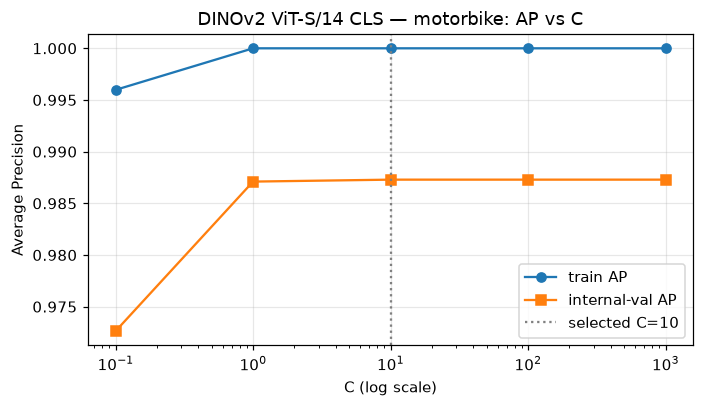

,C,train_ap,val_ap,fit_s,converged,n_iter
0,0.1,0.996,0.9726,0.0094,True,26
1,1.0,1.000,0.9871,0.0117,True,68
2,10.0,1.000,0.9873,0.0118,True,65
3,100.0,1.000,0.9873,0.0117,True,65
4,1000.0,1.000,0.9873,0.0118,True,65


In [7]:
sweep = sweeps[CATEGORY]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.semilogx(sweep["C"], sweep["train_ap"], "o-", label="train AP")
ax.semilogx(sweep["C"], sweep["val_ap"], "s-", label="internal-val AP")
selected = table.loc[table.category == CATEGORY, "C"].iloc[0]
ax.axvline(selected, color="grey", ls=":", label=f"selected C={selected:g}")
ax.set_xlabel("C (log scale)")
ax.set_ylabel("Average Precision")
ax.set_title(f"DINOv2 ViT-S/14 CLS — {CATEGORY}: AP vs C")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

display(sweep.round(4).reset_index(drop=True))

## B.5 — Test ranking and PR curve (target category)

Correct positives in the top 36: 36 / 125


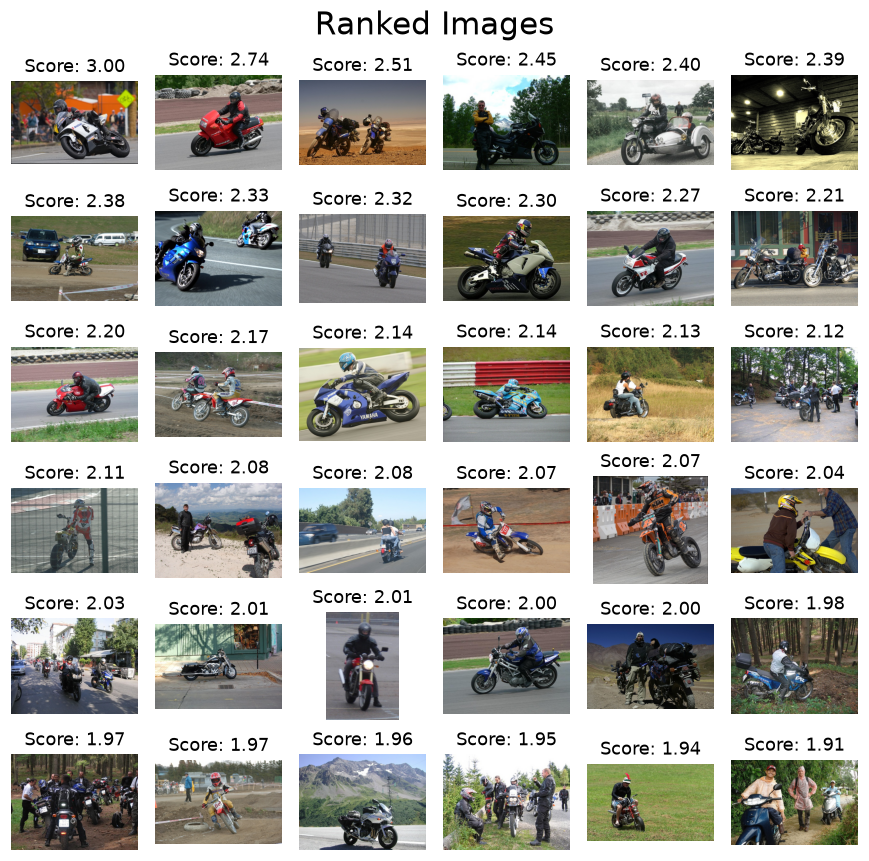

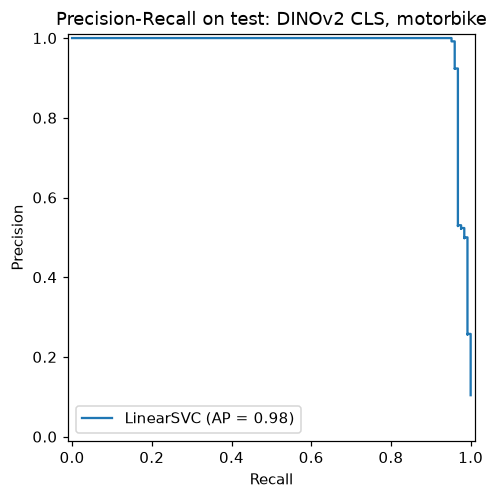

AP on test (motorbike): 0.9818


In [8]:
scores, y_te, n_te = target_pack
paths = [f"data/images/{name}.jpg" for name in n_te]

perm = np.argsort(scores)[::-1]
print("Correct positives in the top 36:", int((y_te[perm[:36]] > 0).sum()), "/", int((y_te > 0).sum()))

displayRankedImageList(scores, paths, uniform=False, figzize=(8, 8))
*_, test_ap = displayPrecisionRecallCurve(
    y_te, scores, title=f"Precision-Recall on test: DINOv2 CLS, {CATEGORY}")
print(f"AP on test ({CATEGORY}): {test_ap:.4f}")

## B.6 — Six-way confusion matrix, accuracy and macro-F1

Same multiclass protocol as Stage A: five object classes plus `background`,
`C` selected by internal-validation macro-F1, report on the test split.

selected C=1  test accuracy=0.8244  macro-F1=0.7647


,C,val_macro_f1,val_accuracy,converged
0,0.1,0.6968,0.7474,True
1,1.0,0.7125,0.7579,True
2,10.0,0.6992,0.7504,True
3,100.0,0.6812,0.7323,False
4,1000.0,0.6486,0.7143,False


,label,precision,recall,f1,support
0,aeroplane,0.8750,1.0000,0.9333,126
1,background,0.8989,0.9656,0.9311,1077
2,car,0.7368,0.7893,0.7622,337
3,horse,0.5789,0.5946,0.5867,148
4,motorbike,0.6167,0.5920,0.6041,125
5,person,0.8248,0.7233,0.7707,983


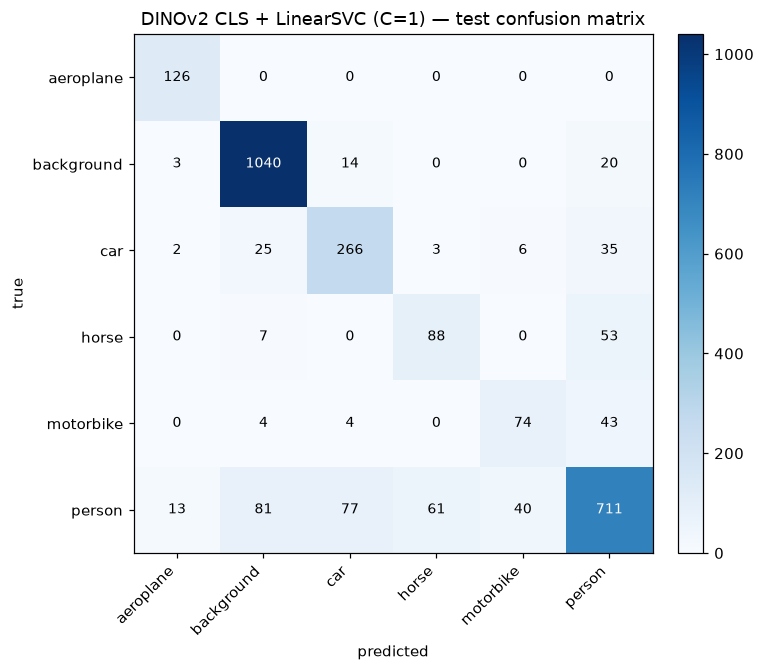

In [9]:
mc, mc_sweep, mc_per_class = evaluate_multiclass(
    train_l2, train_categories, train_names,
    test_l2, test_categories,
    val_names, C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
)

print(f"selected C={mc['C']:g}  test accuracy={mc['accuracy']:.4f}  "
      f"macro-F1={mc['macro_f1']:.4f}")
display(mc_sweep.round(4).reset_index(drop=True))
display(mc_per_class.round(4).reset_index(drop=True))

cm = np.asarray(mc["confusion"])
labels = mc["labels"]
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
ax.set_yticks(range(len(labels)), labels)
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"DINOv2 CLS + LinearSVC (C={mc['C']:g}) — test confusion matrix")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

## B.7 — Normalisation ablation: L2 vs train-set standardisation

The PDF asks for features to be normalised *consistently*. L2 is the default here
(same as Stage A). This cell checks the alternative: standardise each dimension
using mean/std estimated **on the training split only** (internal-validation rows
excluded), then rerun the identical protocol. The primary result stays L2; the
ablation is reported as evidence, not selected on the test set.

In [10]:
norm_rows = [dict(norm="l2", dim=table.dim.iloc[0],
                  AP_target=float(table.loc[table.category == CATEGORY, "test_ap"].iloc[0]),
                  mAP=float(table.test_ap.mean()))]

if RUN_NORMALISATION_ABLATION:
    mu = train_features[~is_val].mean(axis=0, keepdims=True)
    sd = train_features[~is_val].std(axis=0, keepdims=True) + 1e-8
    train_std, test_std = (train_features - mu) / sd, (test_features - mu) / sd

    std_summaries = []
    for cat in CATEGORIES_TO_EVAL:
        X_tr, y_tr, n_tr = binary_subset(cat, train_std, train_names, train_categories)
        X_te, y_te, n_te = binary_subset(cat, test_std, test_names, test_categories)
        summary, _, _ = evaluate_binary(
            cat, X_tr, y_tr, n_tr, X_te, y_te, val_names,
            C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
        )
        std_summaries.append(summary)

    std_table, std_map = per_class_table(std_summaries)
    norm_rows.append(dict(
        norm="train-standardisation", dim=std_table.dim.iloc[0],
        AP_target=float(std_table.loc[std_table.category == CATEGORY, "test_ap"].iloc[0]),
        mAP=std_map))
    save_results(std_table, RESULTS_DIR / f"part4b_{TAG}_standardised_per_class.csv")

norm_df = pd.DataFrame(norm_rows)
display(norm_df.round(4).reset_index(drop=True))
save_results(norm_df, RESULTS_DIR / f"part4b_{TAG}_normalisation_ablation.csv")

,norm,dim,AP_target,mAP
0,l2,384,0.9818,0.9873
1,train-standardisation,384,0.9770,0.9747


WindowsPath('results/part4b_dinov2_vits14_normalisation_ablation.csv')

## B.8 — Pooling ablation: CLS vs mean vs GeM patch tokens

All three descriptors were produced by the same forward pass and are already in
the cache. This answers what a single global descriptor keeps or loses relative
to aggregated patch tokens, and whether the CLS token is the best global summary.
Every variant uses L2 normalisation and the same protocol.

In [11]:
pool_rows = []
if RUN_POOLING_ABLATION:
    for pooling in POOLINGS:
        tr, trn, trc, _ = get_features("train", pooling=pooling)
        te, ten, tec, _ = get_features("val", pooling=pooling)
        rows = []
        for cat in CATEGORIES_TO_EVAL:
            X_tr, y_tr, n_tr = binary_subset(cat, tr, trn, trc)
            X_te, y_te, n_te = binary_subset(cat, te, ten, tec)
            summary, _, _ = evaluate_binary(
                cat, l2norm(X_tr), y_tr, n_tr, l2norm(X_te), y_te, val_names,
                C_grid=C_GRID, max_iter=MAX_ITER, seed=SEED,
            )
            rows.append(summary)
        pool_table, pool_map = per_class_table(rows)
        pool_rows.append(dict(
            pooling=pooling, dim=int(pool_table.dim.iloc[0]),
            AP_target=float(pool_table.loc[pool_table.category == CATEGORY, "test_ap"].iloc[0]),
            mAP=float(pool_map),
            svm_infer_ms_per_img=float(pool_table.infer_ms_per_img.mean())))
        if pooling != "cls":
            save_results(pool_table, RESULTS_DIR / f"part4b_{TAG}_{pooling}_per_class.csv")

pool_df = pd.DataFrame(pool_rows)
display(pool_df.round(4).reset_index(drop=True))
save_results(pool_df, RESULTS_DIR / f"part4b_{TAG}_pooling_ablation.csv")

[cache] data\deep_features\dinov2_vits14\train.npz -> features_cls (2791, 384)
[cache] data\deep_features\dinov2_vits14\val.npz -> features_cls (2796, 384)
[cache] data\deep_features\dinov2_vits14\train.npz -> features_mean (2791, 384)
[cache] data\deep_features\dinov2_vits14\val.npz -> features_mean (2796, 384)
[cache] data\deep_features\dinov2_vits14\train.npz -> features_gem (2791, 384)
[cache] data\deep_features\dinov2_vits14\val.npz -> features_gem (2796, 384)


,pooling,dim,AP_target,mAP,svm_infer_ms_per_img
0,cls,384,0.9818,0.9873,0.0011
1,mean,384,0.9833,0.9876,0.0011
2,gem,384,0.9803,0.9876,0.0010


WindowsPath('results/part4b_dinov2_vits14_pooling_ablation.csv')

## B.9 — Cost and storage

* model loading time is reported separately (it is not a per-image cost);
* extraction cost is measured warm on 64 images, preprocessing included;
* storage is `384 × 4 bytes × N` per pooling (raw) plus the on-disk cache size;
* SVM fit and inference costs come from the per-class runs.

In [12]:
from src.utils import loadSamplesTable

sample_rng = np.random.default_rng(SEED)
sample_idx = sample_rng.choice(len(test_names), size=min(64, len(test_names)), replace=False)
sample_df = loadSamplesTable("data/splits", "data/images", subset="val", per_class=-1)
sample_df = (sample_df[sample_df.filename.isin(test_names[sample_idx])]
             .drop_duplicates("filename").reset_index(drop=True))

_ = extract_split(sample_df)                 # warm-up (CUDA/cuDNN init)
_, warm_s = extract_split(sample_df)
ms_per_img = 1000 * warm_s / len(sample_df)

cache_dir = Path("data/deep_features") / TAG
cache_mb = sum(p.stat().st_size for p in cache_dir.glob("*.npz")) / 1e6

cost = pd.DataFrame([dict(
    representation="DINOv2 ViT-S/14", dim=384,
    model_load_s=model_load_s,
    extract_ms_per_img=ms_per_img,
    svm_train_s=float(table.fit_s.mean()),
    svm_infer_ms_per_img=float(table.infer_ms_per_img.mean()),
    raw_storage_MB=storage_mb(train_features) + storage_mb(test_features),
    disk_cache_MB=cache_mb,
    device=str(device))])
display(cost.round(3).reset_index(drop=True))
save_results(cost, RESULTS_DIR / f"part4b_{TAG}_cost.csv")

  done: 64 images, 384-D, 4.4s (68.9 ms/img, preprocessing included)
  done: 64 images, 384-D, 4.2s (65.5 ms/img, preprocessing included)


,representation,dim,model_load_s,extract_ms_per_img,svm_train_s,svm_infer_ms_per_img,raw_storage_MB,disk_cache_MB,device
0,DINOv2 ViT-S/14,384,1.471,65.514,0.022,0.001,8.582,23.577,cpu


WindowsPath('results/part4b_dinov2_vits14_cost.csv')

## B.10 — Comparison with Stage A and the consolidated table

If `results/part4a_stage_a_summary.csv` exists, the DINOv2 rows are appended to
it; otherwise only the DINOv2 rows are written. The per-class comparison against
the 896-D ResNet-18 shows where the self-supervised representation wins or loses.

In [13]:
dino_rows = [dict(method="DINOv2 ViT-S/14 CLS + SVM",
                  representation="dinov2 cls",
                  supervision="self-supervised + task labels",
                  dim=int(table.dim.iloc[0]),
                  AP_target=float(table.loc[table.category == CATEGORY, "test_ap"].iloc[0]),
                  mAP=float(table.test_ap.mean()),
                  C_target=float(table.loc[table.category == CATEGORY, "C"].iloc[0]),
                  extract_ms_per_img=ms_per_img,
                  svm_infer_ms_per_img=float(table.infer_ms_per_img.mean()),
                  storage_MB=storage_mb(train_features) + storage_mb(test_features))]

if len(pool_df):
    for r in pool_df.itertuples():
        if r.pooling == "cls":
            continue
        dino_rows.append(dict(
            method=f"DINOv2 ViT-S/14 {r.pooling.upper()} + SVM",
            representation=f"dinov2 {r.pooling}",
            supervision="self-supervised + task labels",
            dim=int(r.dim), AP_target=float(r.AP_target), mAP=float(r.mAP),
            C_target=np.nan, extract_ms_per_img=ms_per_img,
            svm_infer_ms_per_img=float(r.svm_infer_ms_per_img),
            storage_MB=storage_mb(train_features) + storage_mb(test_features)))

stage_a_path = RESULTS_DIR / "part4a_stage_a_summary.csv"
if stage_a_path.exists():
    combined = pd.concat([pd.read_csv(stage_a_path), pd.DataFrame(dino_rows)], ignore_index=True)
else:
    combined = pd.DataFrame(dino_rows)

display(combined.round(4).reset_index(drop=True))
save_results(combined, RESULTS_DIR / "part4_stage_a_b_summary.csv")

resnet_path = RESULTS_DIR / "part4a_resnet18_gap896_per_class.csv"
if resnet_path.exists():
    resnet = pd.read_csv(resnet_path)[["category", "test_ap"]].rename(columns={"test_ap": "AP_resnet896"})
    side = table[["category", "test_ap"]].rename(columns={"test_ap": "AP_dinov2_cls"}).merge(
        resnet, on="category", how="left")
    side["delta_dinov2_minus_resnet"] = side.AP_dinov2_cls - side.AP_resnet896
    display(side.round(4).reset_index(drop=True))

,method,representation,supervision,dim,AP_target,mAP,C_target,extract_ms_per_img,svm_infer_ms_per_img,storage_MB
0,ResNet-18 GAP(2/3/4) + SVM,GAP layer2/3/4,pretrained + task labels,896,0.9809,0.9697,10.0,21.3883,0.0026,20.0238
1,ResNet-18 GAP(4) + SVM,GAP layer4,pretrained + task labels,512,0.9806,0.9695,10.0,26.1758,0.0014,11.4422
2,bovw_K512_C0 + SVM,bovw_K512_C0,task labels,2048,0.5507,0.6183,10.0,NaN,0.0006,NaN
3,vlad_K32_C80 + SVM,vlad_K32_C80,task labels,10240,0.7063,0.7168,0.1,NaN,0.0245,NaN
4,fv_K32_C80 + SVM,fv_K32_C80,task labels,20608,0.6862,0.7229,10.0,NaN,0.0044,NaN
5,DINOv2 ViT-S/14 CLS + SVM,dinov2 cls,self-supervised + task labels,384,0.9818,0.9873,10.0,65.5144,0.0011,8.5816
6,DINOv2 ViT-S/14 MEAN + SVM,dinov2 mean,self-supervised + task labels,384,0.9833,0.9876,NaN,65.5144,0.0011,8.5816
7,DINOv2 ViT-S/14 GEM + SVM,dinov2 gem,self-supervised + task labels,384,0.9803,0.9876,NaN,65.5144,0.0010,8.5816


,category,AP_dinov2_cls,AP_resnet896,delta_dinov2_minus_resnet
0,aeroplane,1.0000,0.9723,0.0277
1,car,0.9749,0.9646,0.0104
2,horse,0.9980,0.9568,0.0412
3,motorbike,0.9818,0.9809,0.0010
4,person,0.9820,0.9739,0.0080
